In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df= pd.read_csv("../data/processed/2018_combined.csv")
df.head()

,Timestamp,pressure_n1,pressure_n4,pressure_n31,pressure_n54,pressure_n105,pressure_n114,pressure_n163,pressure_n188,pressure_n215,...,demand_n382,demand_n383,demand_n384,demand_n385,demand_n386,demand_n387,demand_n388,demand_n389,level_T1,Total_Leakage
0,2018-01-01 00:00:00,28.92,33.87,37.13,37.13,50.52,53.99,52.56,55.32,39.09,...,67.61,65.82,65.25,57.39,214.20,81.49,256.50,92.14,3.50,0.0
1,2018-01-01 00:05:00,28.94,33.89,37.16,37.23,50.60,54.09,52.67,55.42,39.10,...,95.29,50.18,81.29,49.67,109.14,104.46,394.48,203.61,3.51,0.0
2,2018-01-01 00:10:00,28.96,33.91,37.18,37.21,50.57,54.05,52.64,55.39,39.09,...,178.10,63.74,252.94,9.69,285.82,94.32,337.33,93.11,3.53,0.0
3,2018-01-01 00:15:00,28.98,33.93,37.19,37.27,50.60,54.08,52.70,55.45,39.09,...,51.60,33.93,139.25,36.15,183.66,57.27,268.74,96.19,3.54,0.0
4,2018-01-01 00:20:00,28.98,33.93,37.19,37.14,50.53,54.00,52.57,55.32,39.09,...,79.05,68.27,43.76,22.05,226.42,140.88,423.29,96.87,3.56,0.0


In [3]:
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum().sum())

(105120, 121)
<class 'pandas.DataFrame'>
RangeIndex: 105120 entries, 0 to 105119
Columns: 121 entries, Timestamp to Total_Leakage
dtypes: float64(120), str(1)
memory usage: 97.0 MB
None
         pressure_n1    pressure_n4   pressure_n31   pressure_n54  \
count  105120.000000  105120.000000  105120.000000  105120.000000   
mean       28.177514      33.264552      36.604953      36.796791   
std         0.548432       0.541586       0.508478       0.739204   
min        25.670000      30.900000      34.590000      34.330000   
25%        27.740000      32.840000      36.190000      36.190000   
50%        28.100000      33.200000      36.550000      36.810000   
75%        28.630000      33.720000      37.030000      37.370000   
max        29.360000      34.310000      37.570000      38.290000   

       pressure_n105  pressure_n114  pressure_n163  pressure_n188  \
count  105120.000000  105120.000000  105120.000000  105120.000000   
mean       50.243409      53.659096      52.139037    

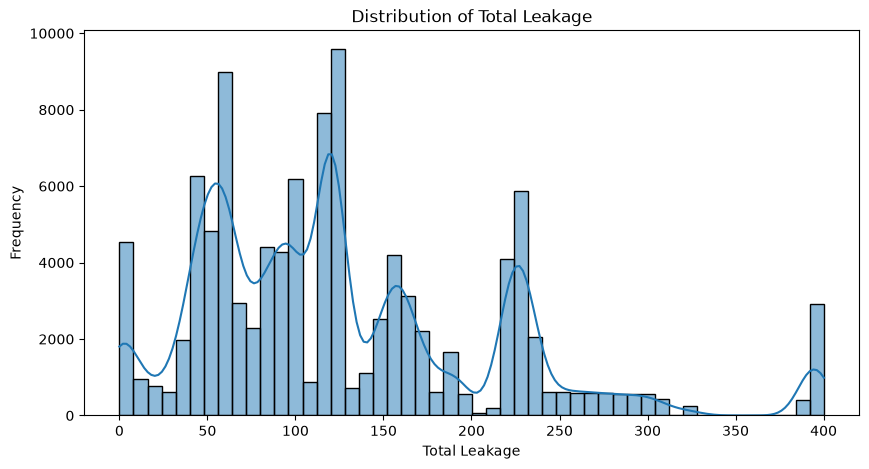

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Total_Leakage"], bins=50, kde=True)

plt.title("Distribution of Total Leakage")
plt.xlabel("Total Leakage")
plt.ylabel("Frequency")
plt.show()

In [16]:
leakage_mean = df["Total_Leakage"].mean()
leakage_median = df["Total_Leakage"].median()
leakage_mode = df["Total_Leakage"].mode()

print(f"Mean: {leakage_mean}")
print(f"Median: {leakage_median}")
print(f"Mode:\n{leakage_mode.to_list()}")

Mean: 127.62033485540333
Median: 119.55
Mode:
[0.0]


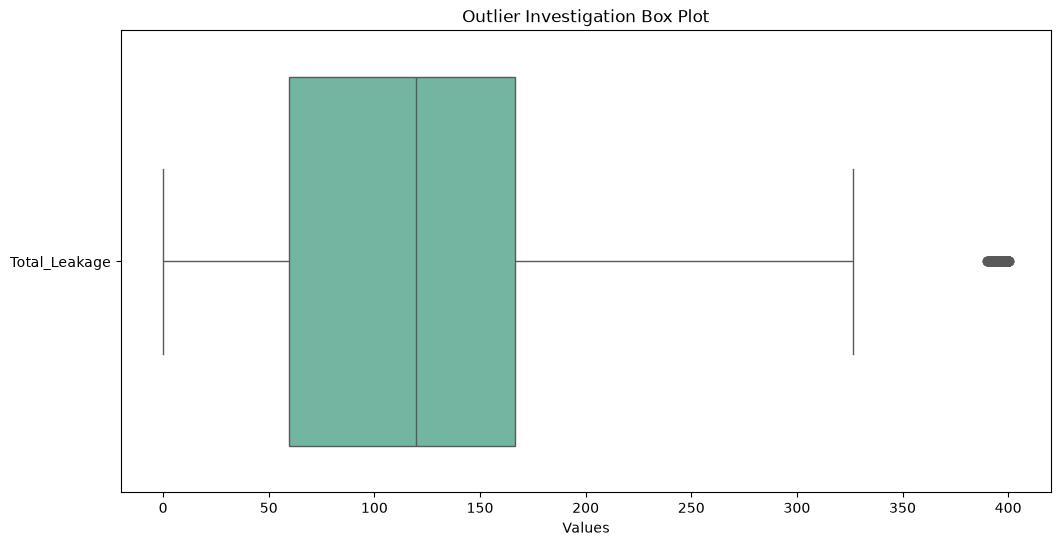

Number of statistical outliers detected: 3322


In [30]:

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[["Total_Leakage"]], orient="h", palette="Set2")
plt.title("Outlier Investigation Box Plot")
plt.xlabel("Values")
plt.show()

Q1 = df["Total_Leakage"].quantile(0.25)
Q3 = df["Total_Leakage"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[
    (df["Total_Leakage"] < (Q1 - 1.5 * IQR))
    | (df["Total_Leakage"] > (Q3 + 1.5 * IQR))
]
print(f"Number of statistical outliers detected: {len(outliers)}")

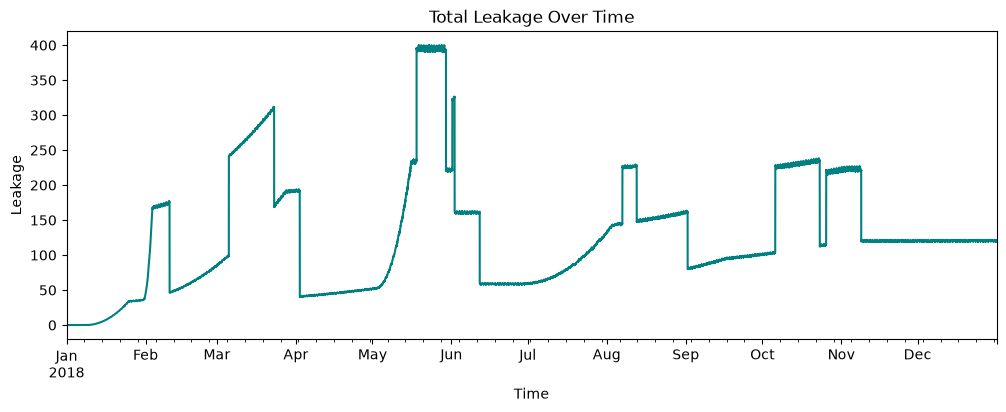

In [23]:
  df["Timestamp"] = pd.to_datetime(df["Timestamp"])
  df.set_index("Timestamp", inplace=True)

  # Plot time series trend for Total Leakage
  plt.figure(figsize=(12, 4))
  df["Total_Leakage"].plot(color="teal")
  plt.title("Total Leakage Over Time")
  plt.ylabel("Leakage")
  plt.xlabel("Time")
  plt.show()

In [24]:
leak_state = df[df["Total_Leakage"] > 0]

print(f"Normal state record count: {len(normal_state)}")
print(f"Leak state record count: {len(leak_state)}")
comparison = pd.DataFrame(
    {"Normal_Mean": normal_state.mean(), "Leak_Mean": leak_state.mean()}
)
print(comparison.head(10))

Normal state record count: 2310
Leak state record count: 102810
               Normal_Mean  Leak_Mean
pressure_n1      28.538615  28.169400
pressure_n4      33.473641  33.259854
pressure_n31     36.780346  36.601012
pressure_n54     37.453113  36.782045
pressure_n105    50.538554  50.236777
pressure_n114    54.006593  53.651288
pressure_n163    52.663545  52.127252
pressure_n188    55.408338  54.877506
pressure_n215    39.091498  39.081359
pressure_n229    52.657515  52.074425


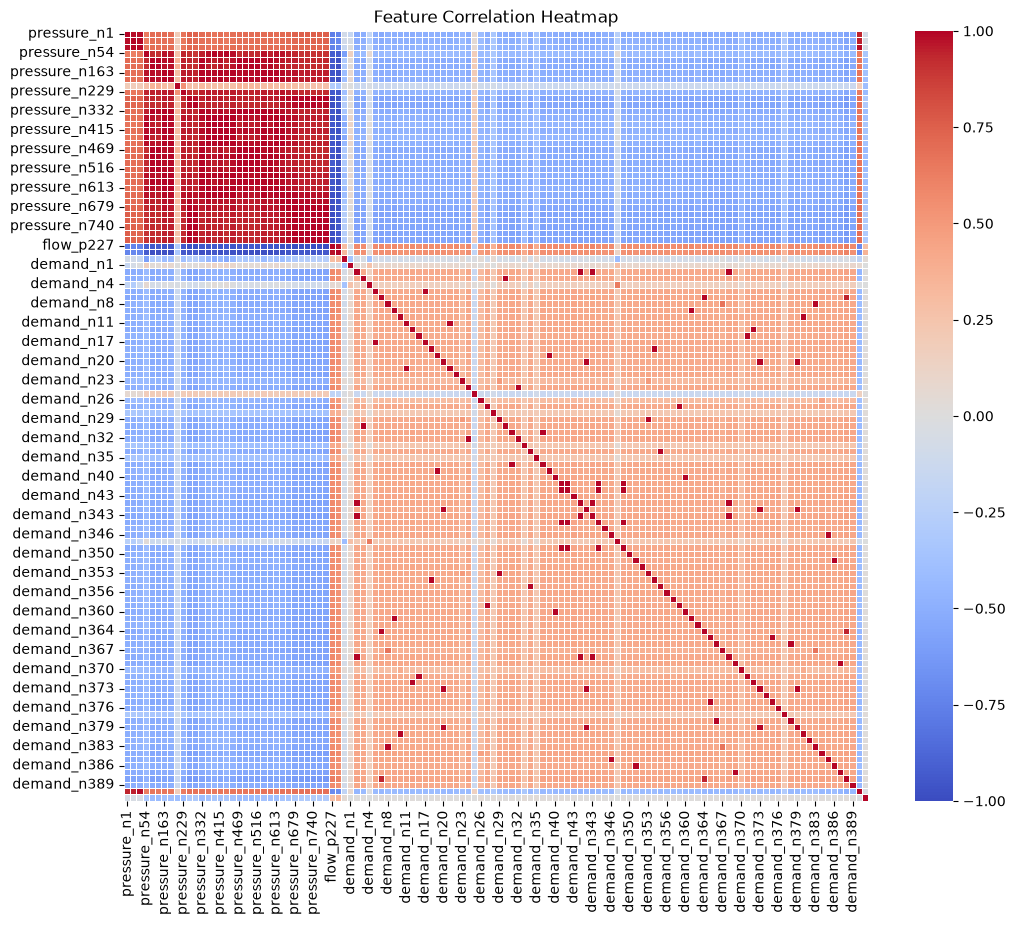

In [28]:

plt.figure(figsize=(12, 10))
correlation_matrix = df.select_dtypes(include=[np.number]).corr()

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Feature Correlation Heatmap")
plt.show()